DATA CLEANING DAN TRANFORMATION

In [1]:
import pandas as pd
wine = pd.read_csv("winequality-red.csv", sep=";")
wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [2]:
wine.describe(include="all")

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [3]:
missing_values = wine.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [4]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [5]:
numeric_features = wine[less].select_dtypes(include=['number']).columns
wine[numeric_features] = wine[numeric_features].fillna(wine[numeric_features].median())

In [6]:
kategorical_features = wine[less].select_dtypes(include=['object']).columns
for column in kategorical_features:
    wine[column] = wine[column].fillna(wine[column].mode()[0])

In [7]:
df = wine.drop(columns=over)

In [8]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

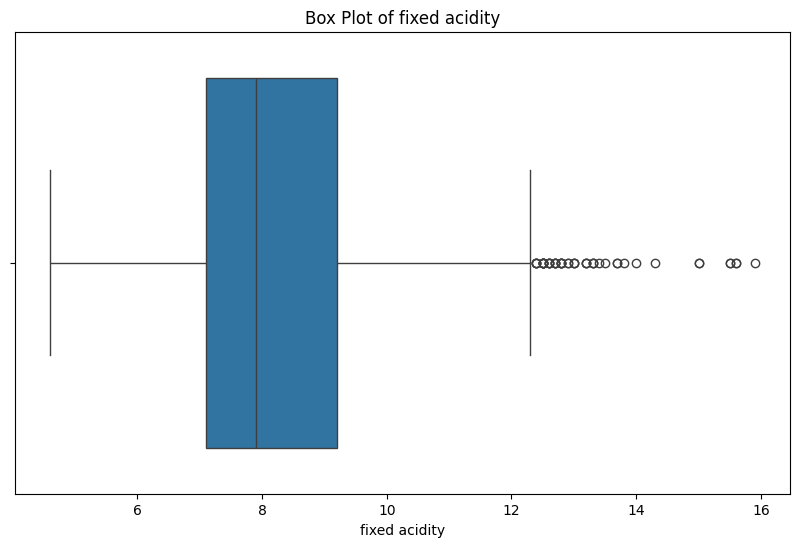

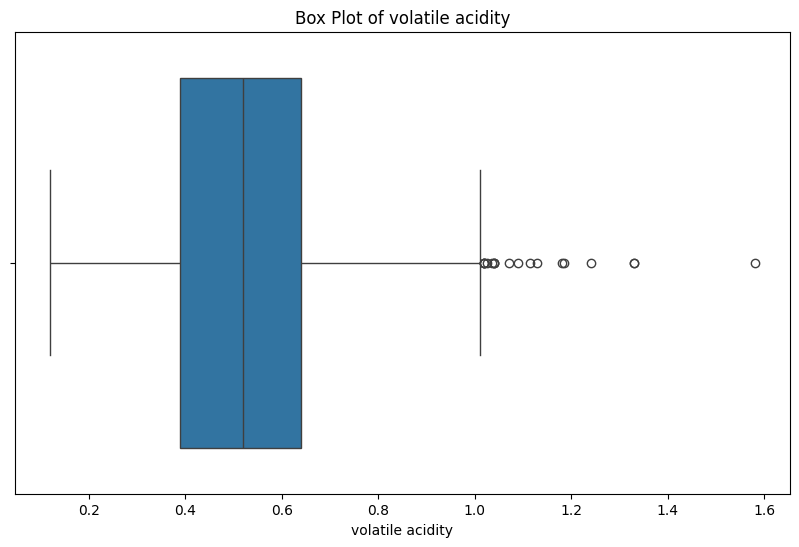

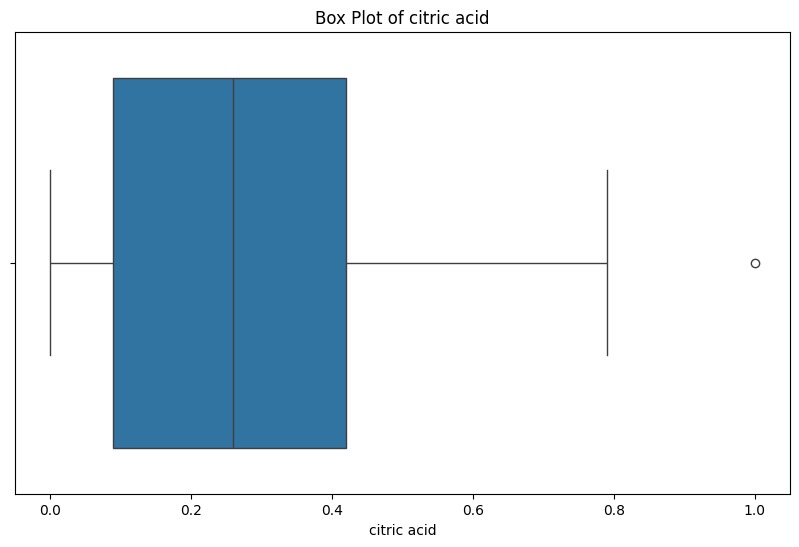

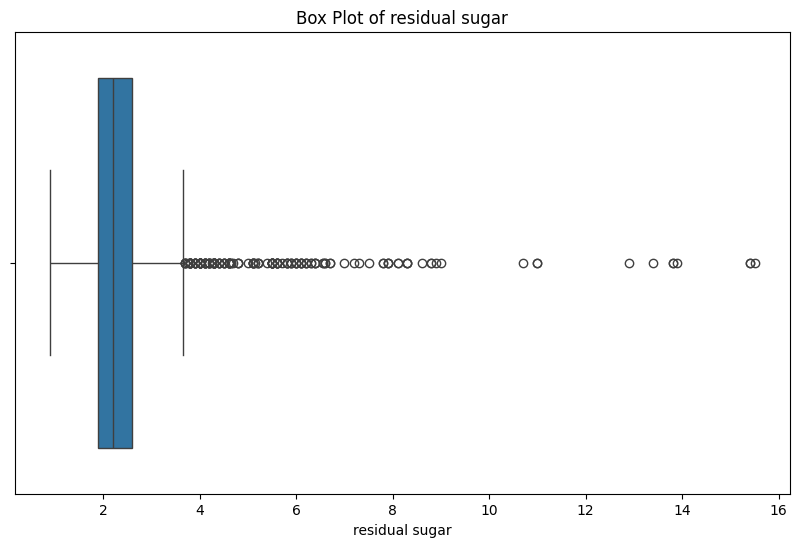

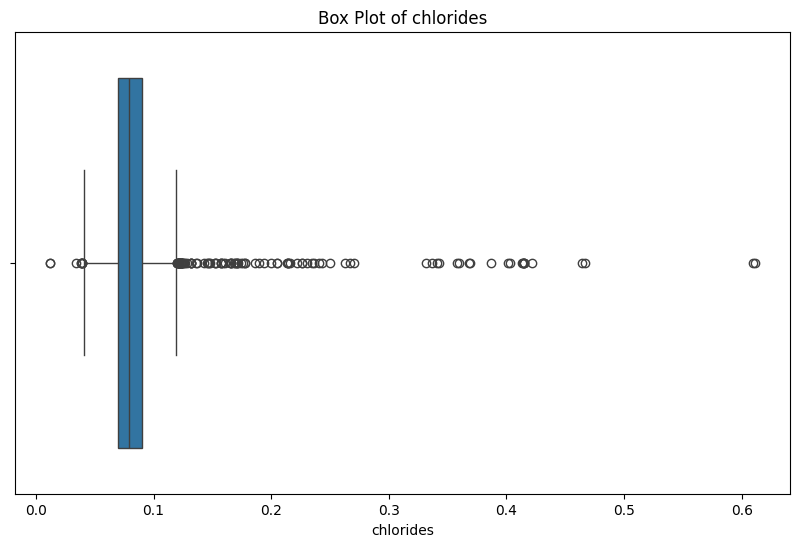

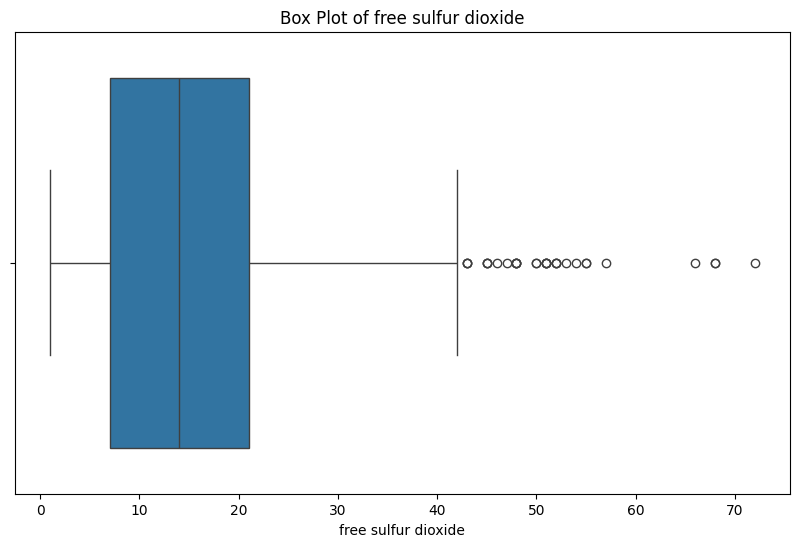

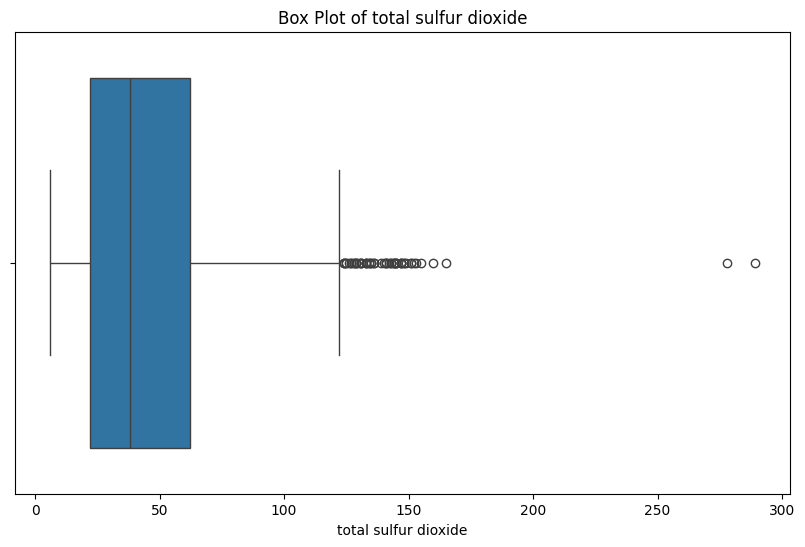

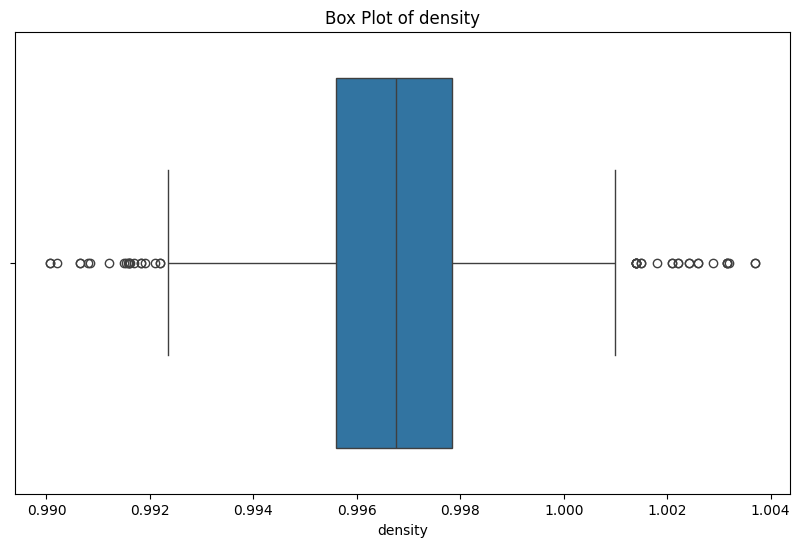

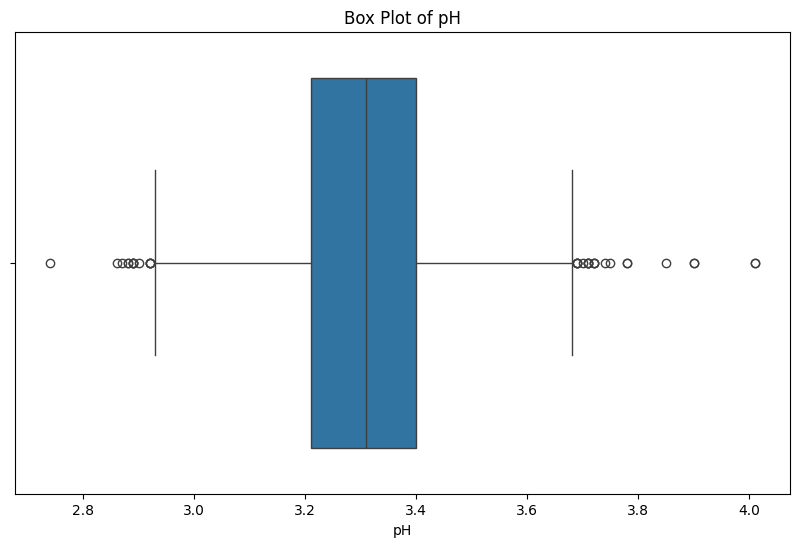

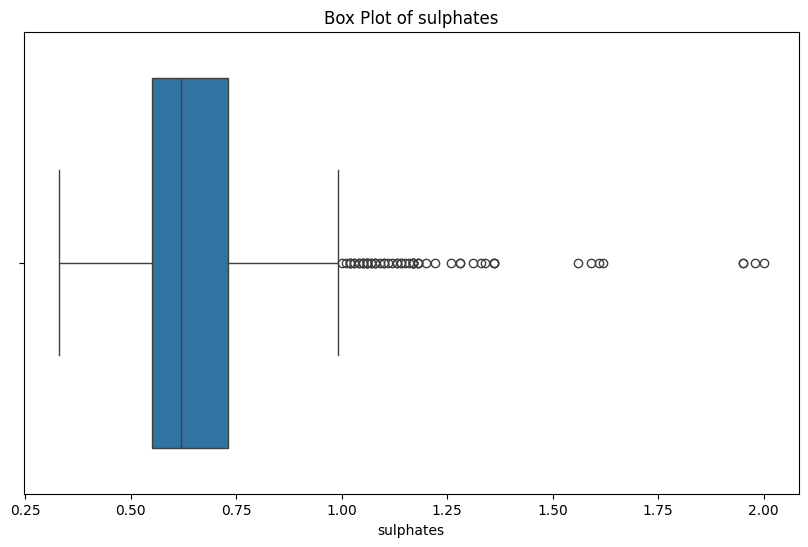

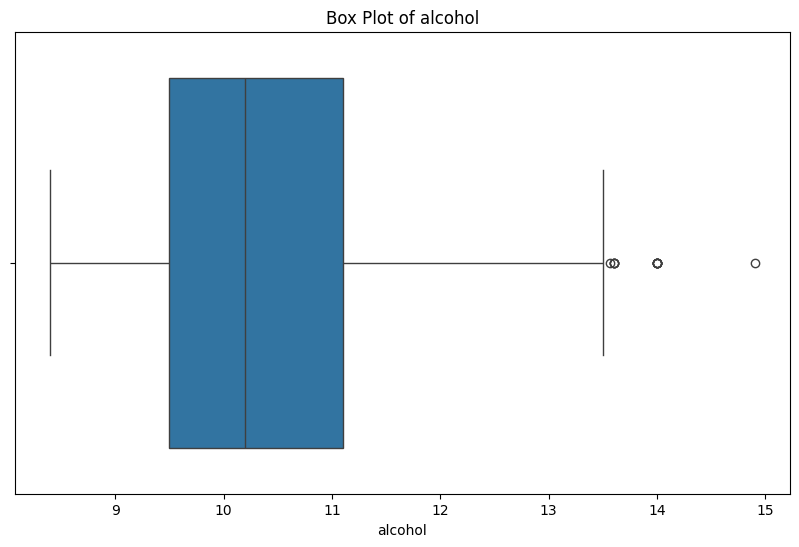

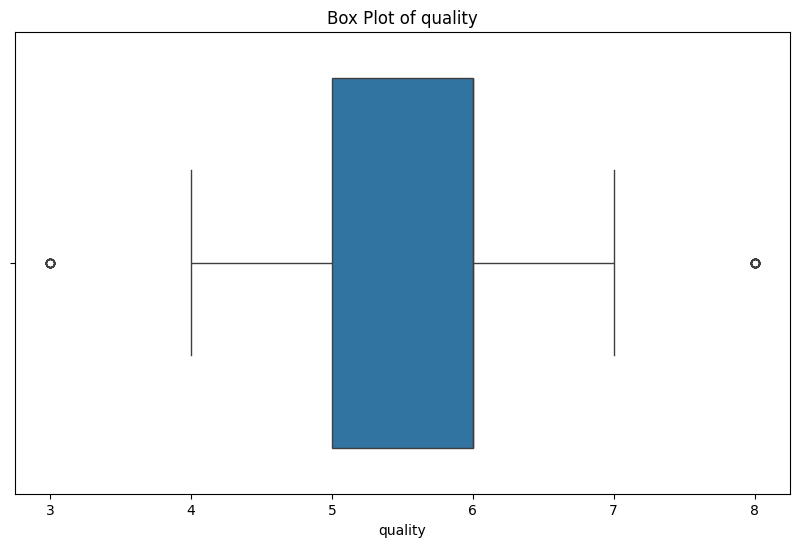

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
        plt.figure(figsize=(10, 6))
        sns.boxplot(x=df[feature])
        plt.title(f'Box Plot of {feature}')
        plt.show()

In [10]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [11]:
condition = ~((df[numeric_features] < (Q1 - 1.5 *IQR)) | (df[numeric_features] > (Q3 + 1.5 * IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

categorical_features = df.select_dtypes(include=['object']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [12]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

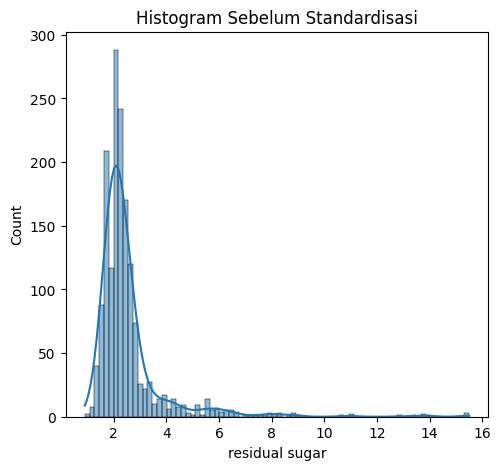

In [13]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(wine[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

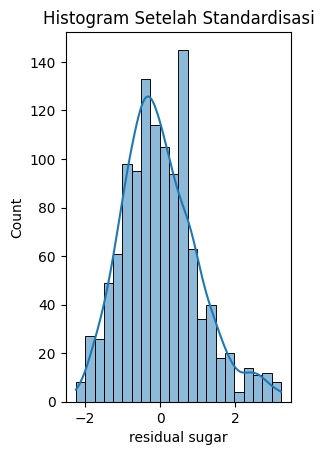

In [14]:
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [15]:
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
4         -0.522760          1.077803    -1.375744       -0.647508  -0.180706   
27        -0.179742         -0.566918    -0.204945       -1.328112   1.915578   
76         0.437689         -0.688749     2.192405        0.033097   1.007188   
93        -0.316949         -0.201424     0.073816       -0.647508  -1.158972   
102       -0.042535          0.133611    -0.372202       -0.647508   0.098799   
...             ...               ...          ...             ...        ...   
1563      -0.659967          1.047345    -0.650964       -0.420639  -0.180706   
1564      -0.659967          1.047345    -0.650964       -0.420639  -0.180706   
1567      -0.659967          1.047345    -0.650964       -0.420639  -0.180706   
1581      -1.346002          0.224985    -0.873973       -1.101244  -1.787857   
1596      -1.277398         -0.079593    -0.650964        0.259965  -0.180706   

      free 

In [16]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0         -0.522760          1.077803    -1.375744       -0.647508  -0.180706   
1         -0.248346          2.174284    -1.375744        0.940570   1.356569   
2         -0.248346          1.443297    -1.152735        0.259965   0.937312   
3          2.084173         -1.480652     1.746386       -0.647508  -0.250582   
5         -0.522760          0.834141    -1.375744       -0.874376  -0.250582   
...             ...               ...          ...             ...        ...   
1593      -0.934381          0.590478    -0.929726       -0.647508  -0.739715   
1594      -1.346002          0.468647    -0.929726       -0.420639   0.797560   
1595      -1.551812          0.164069    -0.818221        0.033097  -1.158972   
1597      -1.551812          0.742767    -0.706716       -0.420639  -0.250582   
1598      -1.483209         -1.297905     1.244615        3.209252  -0.

In [17]:
numeric_features = df.select_dtypes(include=['number']).columns
df[numeric_features]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,-0.522760,1.077803,-1.375744,-0.647508,-0.180706,-0.457421,-0.316839,0.763633,1.407839,-0.614084,-0.986764,-0.864715
1,-0.248346,2.174284,-1.375744,0.940570,1.356569,1.135446,0.947754,0.135771,-0.946440,0.419963,-0.571630,-0.864715
2,-0.248346,1.443297,-1.152735,0.259965,0.937312,-0.002316,0.449581,0.261343,-0.490773,0.161451,-0.571630,-0.864715
3,2.084173,-1.480652,1.746386,-0.647508,-0.250582,0.225236,0.679507,0.889206,-1.250217,-0.441743,-0.571630,0.522359
5,-0.522760,0.834141,-1.375744,-0.874376,-0.250582,-0.229868,-0.086913,0.763633,1.407839,-0.614084,-0.986764,-0.864715
...,...,...,...,...,...,...,...,...,...,...,...,...
1593,-0.934381,0.590478,-0.929726,-0.647508,-0.739715,1.476774,-0.163555,-0.046310,0.724339,1.626350,-0.882981,0.522359
1594,-1.346002,0.468647,-0.929726,-0.420639,0.797560,1.931879,0.066371,-1.057168,0.952172,-0.441743,0.154854,-0.864715
1595,-1.551812,0.164069,-0.818221,0.033097,-1.158972,2.728312,0.334618,-0.919038,1.483784,1.109327,0.881338,0.522359
1597,-1.551812,0.742767,-0.706716,-0.420639,-0.250582,1.931879,0.066371,-0.699287,1.863506,0.678474,-0.156497,-0.864715


In [18]:
# Cek kolom yang ada
print(df.columns.tolist())

# Lihat tipe data
df.dtypes

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                 float64
dtype: object

In [19]:
# Pisahkan fitur dan target
X = df.drop('quality', axis=1)
y = df['quality']

# Lanjut ke train-test split, modeling, dll.

In [20]:
X = df.drop('quality', axis=1)
y = df['quality']

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [23]:
from sklearn.metrics import mean_squared_error, r2_score
y_pred = model.predict(X_test)
print("RMSE:", mean_squared_error(y_test, y_pred)**0.5)
print("R²  :", r2_score(y_test, y_pred))

RMSE: 0.8546608952453462
R²  : 0.2879954157984468


EDA & ExDA

In [24]:
print("Missing values:")
print(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Jumlah data duplikat: 0


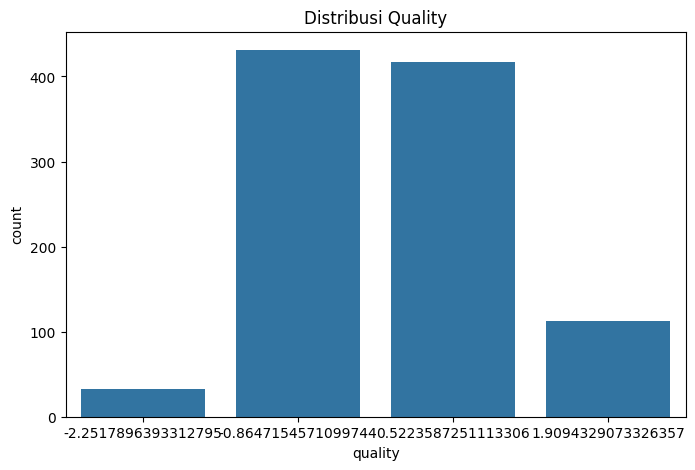

quality
-2.251790     33
-0.864715    431
 0.522359    417
 1.909433    113
Name: count, dtype: int64


In [25]:
plt.figure(figsize=(8,5))
sns.countplot(x='quality', data=df)
plt.title('Distribusi Quality')
plt.show()

print(df['quality'].value_counts().sort_index())

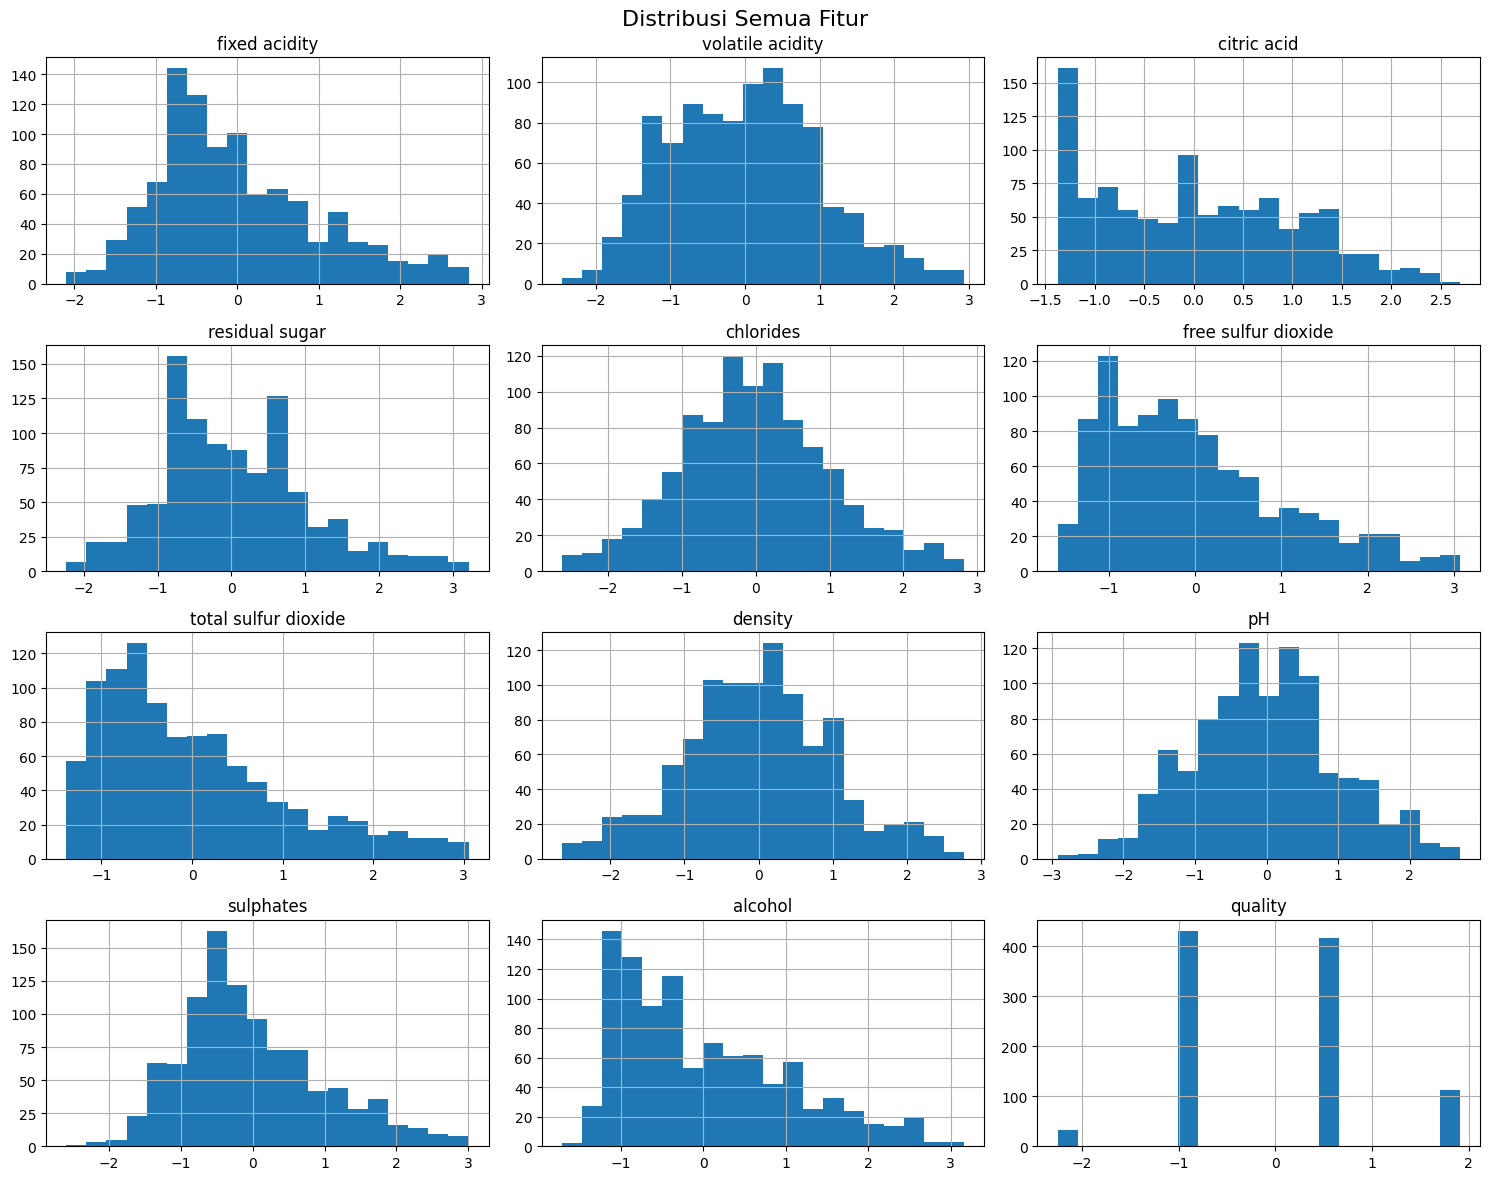

In [26]:
df.hist(bins=20, figsize=(15,12))
plt.suptitle('Distribusi Semua Fitur', fontsize=16)
plt.tight_layout()
plt.show()

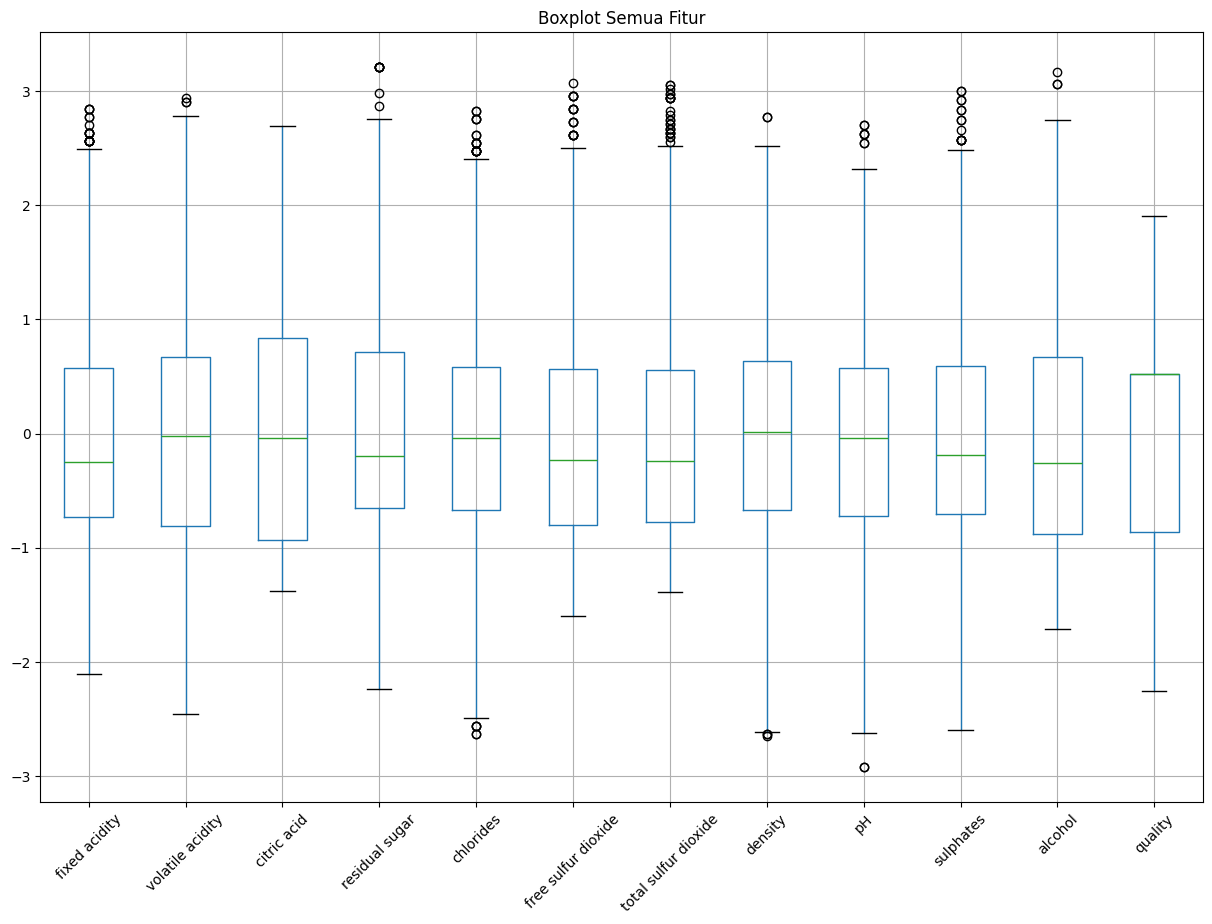

In [27]:
plt.figure(figsize=(15,10))
df.boxplot()
plt.title('Boxplot Semua Fitur')
plt.xticks(rotation=45)
plt.show()

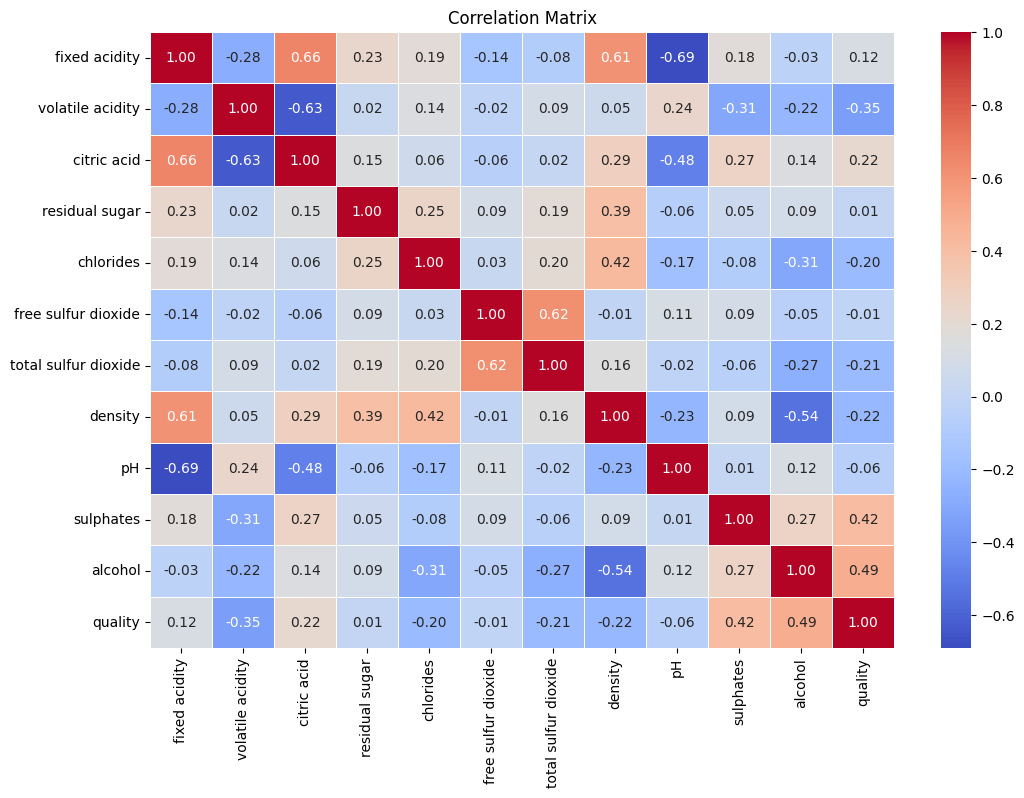

In [28]:
plt.figure(figsize=(12,8))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

quality                 1.000000
alcohol                 0.491520
sulphates               0.417397
citric acid             0.217104
fixed acidity           0.120929
residual sugar          0.006955
free sulfur dioxide    -0.014163
pH                     -0.060759
chlorides              -0.202626
total sulfur dioxide   -0.207148
density                -0.215524
volatile acidity       -0.352585
Name: quality, dtype: float64


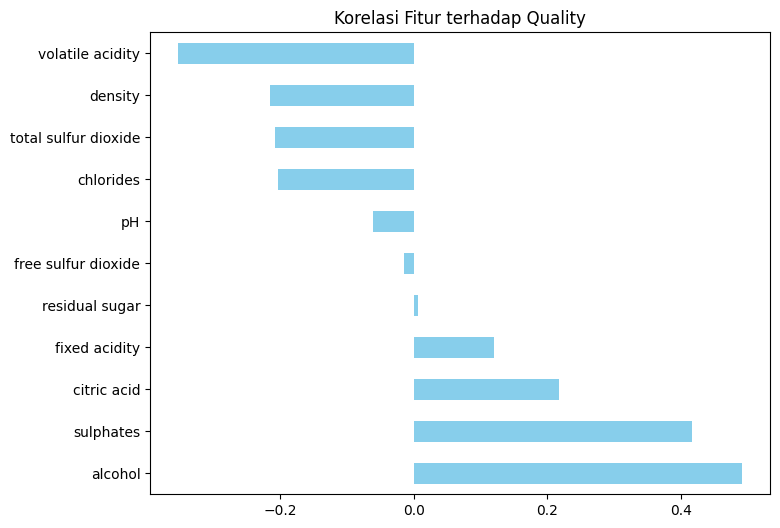

In [29]:
corr_quality = df.corr()['quality'].sort_values(ascending=False)
print(corr_quality)

# Visualisasi
plt.figure(figsize=(8,6))
corr_quality.drop('quality').plot(kind='barh', color='skyblue')
plt.title('Korelasi Fitur terhadap Quality')
plt.show()

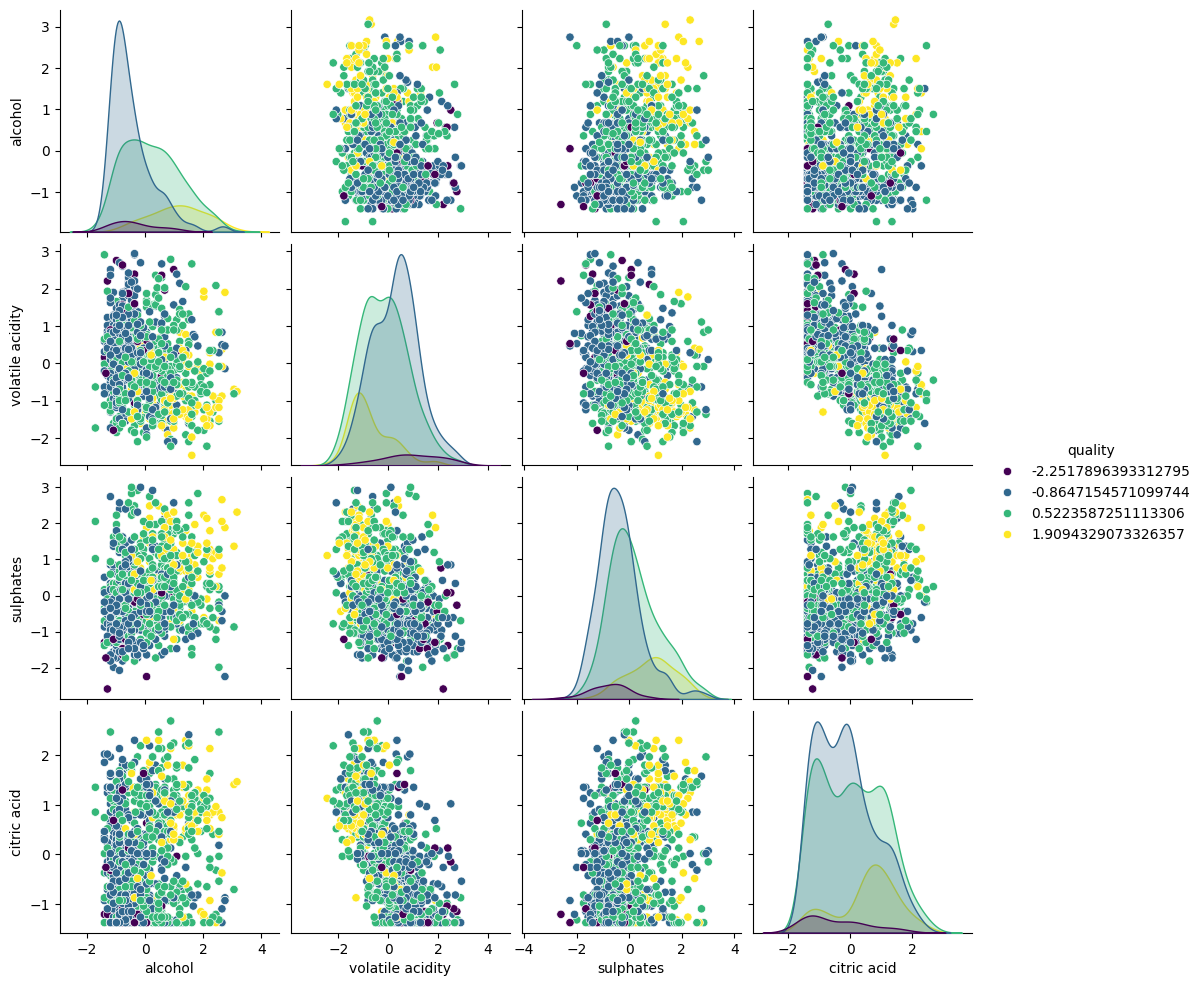

In [30]:
important_features = ['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'quality']
sns.pairplot(df[important_features], hue='quality', palette='viridis')
plt.show()

DATA SPITTING

In [31]:
import sklearn

In [32]:
X = df.drop('quality', axis=1)   
y = df['quality']                

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2,        
    random_state=42,      
    # stratify=y          
)

In [34]:
print("Shape X_train :", X_train.shape)
print("Shape X_test  :", X_test.shape)
print("Shape y_train :", y_train.shape)
print("Shape y_test  :", y_test.shape)

print("\nProporsi quality di y_train:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nProporsi quality di y_test:")
print(y_test.value_counts(normalize=True).sort_index())

Shape X_train : (795, 11)
Shape X_test  : (199, 11)
Shape y_train : (795,)
Shape y_test  : (199,)

Proporsi quality di y_train:
quality
-2.251790    0.033962
-0.864715    0.442767
 0.522359    0.412579
 1.909433    0.110692
Name: proportion, dtype: float64

Proporsi quality di y_test:
quality
-2.251790    0.030151
-0.864715    0.396985
 0.522359    0.447236
 1.909433    0.125628
Name: proportion, dtype: float64


KONVERSI PANDAS DATA FRAME

In [35]:
import os
os.listdir

<function nt.listdir(path=None)>

In [36]:
import pandas as pd

In [37]:
df = pd.read_csv('winequality-red.csv', sep=';')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
